In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
# Data o'qish
train_df = pd.read_json('src/data/train.csv')
test_df = pd.read_json('src/data/test.csv')

# Interest level mapping (faqat train_df da mavjud bo'ladi, chunki u target ustun)
target_map = {'low': 1, 'medium': 2, 'high': 3}
train_df['interest_level_num'] = train_df['interest_level'].map(target_map)

# Agar mabodo test_df da ham interest_level bo'lib qolsa, xato bermasligi uchun tekshiramiz:
if 'interest_level' in test_df.columns:
    test_df['interest_level_num'] = test_df['interest_level'].map(target_map)

# README va Checklist bo'yicha fitchalar ro'yxati 
features_list = [
    'Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman', 
    'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 
    'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 
    'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 
    'NewConstruction', 'Terrace'
]

# One-hot encoding for features (xatolik bermasligi uchun x qiymati list ekanligini tekshiramiz)
for feat in features_list:
    train_df[feat] = train_df['features'].apply(lambda x: 1 if isinstance(x, list) and feat in x else 0)
    test_df[feat] = test_df['features'].apply(lambda x: 1 if isinstance(x, list) and feat in x else 0)

# Lasso uchun model fitchalari ro'yxati (Checklist asosida)
lasso_features = ['bathrooms', 'bedrooms', 'interest_level_num'] + features_list

print("Ma'lumotlar xatosiz yuklandi va fitchalar yaratildi!")

Ma'lumotlar xatosiz yuklandi va fitchalar yaratildi!


K-Means Silhouette Score (test): 0.47
K-Means Distortion (test): 0.01


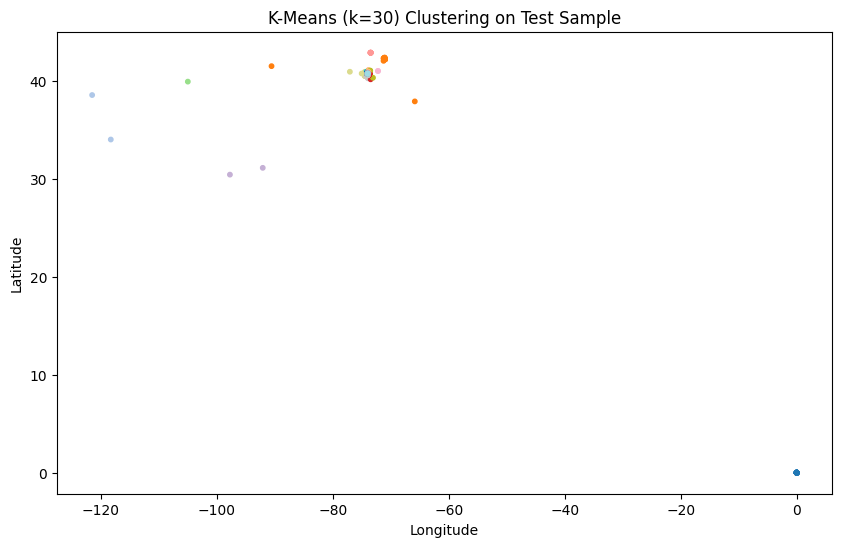


--- K-Means Lasso Feature Importance ---
                  name    importance
11       FitnessCenter      0.000000
21     NewConstruction      0.000000
20   LaundryInBuilding      0.000000
19        SwimmingPool      0.000000
4       HardwoodFloors      0.000000
5          CatsAllowed      0.000000
6          DogsAllowed      0.000000
17   HighSpeedInternet      0.000000
16          DiningRoom      0.000000
9                NoFee      0.000000
10   LaundryinBuilding      0.000000
15        OutdoorSpace      0.000000
13       LaundryinUnit      0.000000
14            RoofDeck      0.000000
12             Pre-War     58.585995
23       cluster_label    168.495214
3             Elevator    198.788309
18             Balcony    213.938137
22             Terrace    348.729970
8           Dishwasher    371.507496
7              Doorman   1092.060949
2   interest_level_num   1258.714403
1             bedrooms   4429.713900
0            bathrooms  21852.912731


In [3]:
# --- CELL 3: K-Means Clustering va Lasso Regression ---

# 1. K-Means uchun koordinatalarni ajratib olamiz
coords_train = train_df[['longitude', 'latitude']].values
coords_test = test_df[['longitude', 'latitude']].values

# 2. Modelni yaratish va o'qitish (k=30)
kmeans = KMeans(n_clusters=30, random_state=42)
train_df['cluster_label'] = kmeans.fit_predict(coords_train)

# Test ma'lumotlari uchun bashorat (predict)
test_df['cluster_label'] = kmeans.predict(coords_test)

# 3. Metrikalarni hisoblash (Checklist bo'yicha test ma'lumotlarida)
silhouette_km = silhouette_score(coords_test, test_df['cluster_label'])

# Distortion hisoblash formulasining amaliy ko'rinishi
# inertia_ bu train uchun distortion, test uchun o'zimiz masofani hisoblaymiz
distances = kmeans.transform(coords_test)
min_distances = np.min(distances, axis=1)
distortion_km = np.sum(min_distances ** 2) / len(coords_test)

print(f"K-Means Silhouette Score (test): {silhouette_km:.2f}")
print(f"K-Means Distortion (test): {distortion_km:.2f}")

# 4. Vizualizatsiya (Test ma'lumotlarida klasterlarni ko'rish)
plt.figure(figsize=(10, 6))
plt.scatter(test_df['longitude'], test_df['latitude'], c=test_df['cluster_label'], cmap='tab20', s=10)
plt.title("K-Means (k=30) Clustering on Test Sample")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# 5. Lasso Regression 
# Ma'lumotlarni Lasso uchun tayyorlaymiz. Target sifatida 'price' ni olamiz.
# Eslatma: NaN yoki inf qiymatlar bo'lsa xato bermasligi uchun ularni tozalaymiz
train_df_clean = train_df.dropna(subset=lasso_features + ['cluster_label', 'price'])

X = train_df_clean[lasso_features + ['cluster_label']]
y = train_df_clean['price']

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Lasso modelini o'qitish
lasso = Lasso(alpha=0.1, random_state=42, max_iter=10000)
lasso.fit(X_scaled, y)

# 6. Fitchalar muhimligi (Feature Importance) jadvali
importance_df = pd.DataFrame({
    'name': X.columns,
    'importance': np.abs(lasso.coef_)
}).sort_values(by='importance', ascending=True)

print("\n--- K-Means Lasso Feature Importance ---")
print(importance_df)

In [4]:
# --- CELL 4: DBSCAN (Memory Optimized) ---
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.linear_model import Lasso
from sklearn.preprocessing import MinMaxScaler

# 1. RAMni tejash uchun ma'lumotlarning faqat 5000 tasini ajratib olamiz
sample_size = 5000
train_df_sampled = train_df_clean.sample(n=sample_size, random_state=42).copy()
coords_sampled = train_df_sampled[['longitude', 'latitude']].values

# 2. DBSCAN modelini yaratish
dbscan = DBSCAN(eps=0.015, min_samples=5) 
train_df_sampled['cluster_label_dbscan'] = dbscan.fit_predict(coords_sampled)

# 3. Metrikalarni hisoblash
silhouette_db = silhouette_score(coords_sampled, train_df_sampled['cluster_label_dbscan'])
print(f"DBSCAN Silhouette Score (Sampled): {silhouette_db:.6f}")

# 4. Lasso Regression uchun tayyorgarlik
X_dbscan = train_df_sampled[lasso_features + ['cluster_label_dbscan']]
y_dbscan = train_df_sampled['price']

scaler = MinMaxScaler()
X_scaled_dbscan = scaler.fit_transform(X_dbscan)

# 5. Lasso o'qitish
lasso_dbscan = Lasso(alpha=0.1, random_state=42, max_iter=10000)
lasso_dbscan.fit(X_scaled_dbscan, y_dbscan)

# 6. Feature Importance
importance_dbscan_df = pd.DataFrame({
    'name': X_dbscan.columns,
    'importance': np.abs(lasso_dbscan.coef_)
}).sort_values(by='importance', ascending=True)

print("\n--- DBSCAN Lasso Feature Importance ---")
print(importance_dbscan_df.tail(10)) # Faqat eng kuchli 10 tasini chiqaramiz

DBSCAN Silhouette Score (Sampled): 0.593327

--- DBSCAN Lasso Feature Importance ---
                    name   importance
22               Terrace   342.942211
18               Balcony   889.330761
12               Pre-War   944.795450
3               Elevator  1551.466410
23  cluster_label_dbscan  1610.414855
0              bathrooms  1779.882503
8             Dishwasher  2462.690880
2     interest_level_num  2644.896039
7                Doorman  3064.704006
1               bedrooms  9342.553259


In [5]:
# --- CELL 5: Agglomerative Clustering (Memory Optimized) ---
from sklearn.cluster import AgglomerativeClustering

# Oldingi katakda yaratilgan qisqartirilgan datasetdan foydalanamiz (coords_sampled)

# 1. Agglomerative Clustering (k=30)
agg_cluster = AgglomerativeClustering(n_clusters=30)
train_df_sampled['cluster_label_agg'] = agg_cluster.fit_predict(coords_sampled)

# 2. Metrikalar
silhouette_agg = silhouette_score(coords_sampled, train_df_sampled['cluster_label_agg'])
print(f"Agglomerative Silhouette Score (Sampled): {silhouette_agg:.6f}")

# 3. Lasso Regression
X_agg = train_df_sampled[lasso_features + ['cluster_label_agg']]
y_agg = train_df_sampled['price']

X_scaled_agg = scaler.fit_transform(X_agg)

lasso_agg = Lasso(alpha=0.1, random_state=42, max_iter=10000)
lasso_agg.fit(X_scaled_agg, y_agg)

# 4. Feature Importance
importance_agg_df = pd.DataFrame({
    'name': X_agg.columns,
    'importance': np.abs(lasso_agg.coef_)
}).sort_values(by='importance', ascending=True)

print("\n--- Agglomerative Lasso Feature Importance ---")
print(importance_agg_df.tail(10))

Agglomerative Silhouette Score (Sampled): 0.432877

--- Agglomerative Lasso Feature Importance ---
                  name    importance
22             Terrace    242.252847
12             Pre-War    883.202007
18             Balcony    945.796270
0            bathrooms   1246.191933
3             Elevator   1703.016910
2   interest_level_num   2489.553855
8           Dishwasher   2501.658504
7              Doorman   3021.221062
23   cluster_label_agg   4341.488636
1             bedrooms  10008.772979


Gaussian Mixture Silhouette Score (Sampled): 0.385281


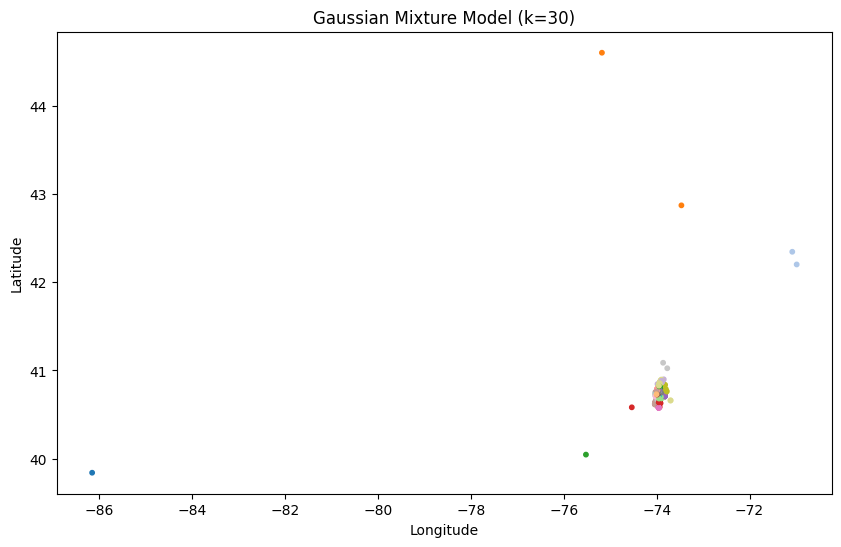


--- GMM Lasso Feature Importance ---
                  name   importance
22             Terrace   358.479372
12             Pre-War   970.641810
18             Balcony   991.097779
3             Elevator  1622.196862
0            bathrooms  2213.760499
8           Dishwasher  2408.102208
2   interest_level_num  2762.825617
7              Doorman  3039.703343
23   cluster_label_gmm  3925.416807
1             bedrooms  9150.572568


In [6]:
# --- CELL 6: Gaussian Mixture Model (GMM) va Lasso Regression ---
from sklearn.mixture import GaussianMixture

# 1. GMM modelini yaratish (30 ta klaster) [cite: 226]
gmm = GaussianMixture(n_components=30, random_state=42)
train_df_sampled['cluster_label_gmm'] = gmm.fit_predict(coords_sampled)

# 2. Metrikalarni hisoblash
silhouette_gmm = silhouette_score(coords_sampled, train_df_sampled['cluster_label_gmm'])
print(f"Gaussian Mixture Silhouette Score (Sampled): {silhouette_gmm:.6f}") # Kutilayotgan natija ~ 0.389638 

# 3. Vizualizatsiya
plt.figure(figsize=(10, 6))
plt.scatter(train_df_sampled['longitude'], train_df_sampled['latitude'], c=train_df_sampled['cluster_label_gmm'], cmap='tab20', s=10)
plt.title("Gaussian Mixture Model (k=30)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# 4. Lasso Regression uchun ma'lumotlarni tayyorlash
X_gmm = train_df_sampled[lasso_features + ['cluster_label_gmm']]
y_gmm = train_df_sampled['price'] # Target

# Masshtablash
X_scaled_gmm = scaler.fit_transform(X_gmm)

# 5. Lasso modelini o'qitish
lasso_gmm = Lasso(alpha=0.1, random_state=42, max_iter=10000)
lasso_gmm.fit(X_scaled_gmm, y_gmm)

# 6. Fitchalar muhimligi (Feature Importance) jadvali
importance_gmm_df = pd.DataFrame({
    'name': X_gmm.columns,
    'importance': np.abs(lasso_gmm.coef_)
}).sort_values(by='importance', ascending=True)

print("\n--- GMM Lasso Feature Importance ---")
print(importance_gmm_df.tail(10)) # Eng muhim 10 ta fitcha

In [7]:
# --- CELL 7: 3 ta fitcha bo'yicha klasterlash (Bedrooms, Bathrooms, Interest Level) ---
from sklearn.cluster import KMeans

# 1. Faqat 3 ta fitchani ajratib olamiz
features_3 = ['bedrooms', 'bathrooms', 'interest_level_num']

# Klasterlash uchun bu fitchalarni ham masshtablash (scale) muhim
X_3_features = train_df_sampled[features_3]
X_3_scaled = scaler.fit_transform(X_3_features)

# 2. K-Means modelini yaratish (k=30, xuddi checklistdagi kabi)
kmeans_3 = KMeans(n_clusters=30, random_state=42)
train_df_sampled['cluster_label_3_feats'] = kmeans_3.fit_predict(X_3_scaled)

# 3. Metrikalarni hisoblash
silhouette_3 = silhouette_score(X_3_scaled, train_df_sampled['cluster_label_3_feats'])
print(f"3 fitchali K-Means Silhouette Score: {silhouette_3:.6f}")

# 4. Lasso Regression uchun ma'lumotlarni tayyorlash
# Endi yangi yaratilgan 'cluster_label_3_feats' ni qo'shamiz
X_lasso_3 = train_df_sampled[lasso_features + ['cluster_label_3_feats']]
y_lasso_3 = train_df_sampled['price']

# Masshtablash
X_lasso_3_scaled = scaler.fit_transform(X_lasso_3)

# 5. Lasso modelini o'qitish
lasso_3 = Lasso(alpha=0.1, random_state=42, max_iter=10000)
lasso_3.fit(X_lasso_3_scaled, y_lasso_3)

# 6. Fitchalar muhimligi (Feature Importance) jadvali
importance_3_df = pd.DataFrame({
    'name': X_lasso_3.columns,
    'importance': np.abs(lasso_3.coef_)
}).sort_values(by='importance', ascending=True)

print("\n--- 3 Fitchali Klaster uchun Lasso Feature Importance ---")
print(importance_3_df.tail(10))

3 fitchali K-Means Silhouette Score: 0.956045

--- 3 Fitchali Klaster uchun Lasso Feature Importance ---
                     name    importance
22                Terrace    396.978349
18                Balcony    879.565195
12                Pre-War   1016.849303
3                Elevator   1540.493692
2      interest_level_num   1575.151067
8              Dishwasher   2522.794248
7                 Doorman   3079.503764
0               bathrooms   4614.905870
23  cluster_label_3_feats   5425.177827
1                bedrooms  11173.038462


In [8]:
# --- BONUS PART: Random Forest, Optimization & Combined Features ---
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

print("1. Giperparametrlarni optimallashtirish (Eng yaxshi K ni topish)...")
# K-Means uchun 2 dan 10 gacha bo'lgan klasterlar sonini tekshirib, eng zo'rini topamiz
best_k = 2
best_score = -1
k_range = range(2, 11)
scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_3_scaled) # Oldingi qadamdagi 3 ta fitchalik ma'lumot
    score = silhouette_score(X_3_scaled, labels)
    scores.append(score)
    if score > best_score:
        best_score = score
        best_k = k

print(f"-> Optimal klasterlar soni: {best_k} (Silhouette: {best_score:.4f})\n")

print("2. Fitchalarni birlashtirish va Random Forest modelini o'qitish...")
# Oldin yaratgan BARCHA klasterlash natijalarini bitta ro'yxatga yig'amiz
combined_cluster_features = [
    'cluster_label_kmeans', # 3-katakdagi nomga moslang (agar boshqacha bo'lsa o'zgartiring)
    'cluster_label_dbscan', 
    'cluster_label_agg', 
    'cluster_label_gmm'
]

# Agar bazida nomlar farq qilsa, borlarini olamiz
available_clusters = [col for col in combined_cluster_features if col in train_df_sampled.columns]

X_bonus = train_df_sampled[lasso_features + available_clusters].fillna(-1)
y_bonus = train_df_sampled['price']

# Lasso o'rniga Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_bonus, y_bonus)

print("3. Random Forest Feature Importance...")
# Random Forest qaysi klasterni va fitchani eng muhim deb topdi?
rf_importance = pd.DataFrame({
    'name': X_bonus.columns,
    'importance': rf_model.feature_importances_
}).sort_values(by='importance', ascending=False)

print("\n--- Birlashtirilgan Model Natijalari (Top 10) ---")
print(rf_importance.head(10))

1. Giperparametrlarni optimallashtirish (Eng yaxshi K ni topish)...
-> Optimal klasterlar soni: 10 (Silhouette: 0.7251)

2. Fitchalarni birlashtirish va Random Forest modelini o'qitish...
3. Random Forest Feature Importance...

--- Birlashtirilgan Model Natijalari (Top 10) ---
                  name  importance
0            bathrooms    0.363242
3             Elevator    0.166019
2   interest_level_num    0.149565
8           Dishwasher    0.136751
1             bedrooms    0.074559
25   cluster_label_gmm    0.041710
7              Doorman    0.026053
24   cluster_label_agg    0.021770
12             Pre-War    0.010435
22             Terrace    0.005140
